# 02. Модели прогноза выдачи наличных

**Задача:** вечером, зная всё о прошлых днях и календарь на завтра, предсказать, **сколько наличных выдаст каждый банкомат завтра** (`cash_out`, сом).

**План:**
1. Признаки: календарь, погода, тип и район банкомата, история выдачи (лаги и скользящие средние), недавние скачки курса.
2. Разбиение по времени: учим на данных **до 30.06.2025**, проверяем на **01.07–31.12.2025** (полгода, которые модель «не видела»).
3. Четыре модели — от самой простой к сложной: naive → среднее по дню недели → Ridge → LightGBM.
4. Сравниваем по MAE / MAPE / WAPE, смотрим, что важно для модели, и рисуем прогноз против факта.

Вход: `data/processed/daily.parquet` из ноутбука 01.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2,
})
thousands = mticker.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}".replace(",", " "))

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

SEED = 42
TRAIN_END = pd.Timestamp("2025-06-30")
TEST_START = pd.Timestamp("2025-07-01")

df = pd.read_parquet(ROOT / "data" / "processed" / "daily.parquet")
df = df.sort_values(["atm_id", "date"]).reset_index(drop=True)
print(df.shape, df.date.min().date(), "…", df.date.max().date())

(82565, 39) 2024-01-01 … 2025-12-31


## 1. Признаки

Главное правило — **никаких подсказок из будущего**. Прогноз на день D делаем вечером дня D−1, поэтому:

| Группа | Признаки | Почему можно использовать |
|---|---|---|
| Календарь дня D | день недели, праздник, предпраздник, зарплата, пенсия, Рамадан | известен заранее |
| Погода | температура, осадки, снег, ветер **вчера (D−1)** | фактическая погода дня D известна только после дня, поэтому берём вчерашнюю |
| Банкомат | тип точки, район, на улице ли | не меняется |
| История выдачи | лаги 1, 7, 14 дней; скользящие средние за 7 и 28 дней (по D−1 включительно) | всё в прошлом |
| Курс | был ли скачок курса за последние 3 дня (D−3 … D−1) | курс дня D заранее неизвестен |

**Дни сбоев в истории.** Если банкомат вчера был пустым или в простое, его вчерашняя выдача — не настоящий спрос. Для скользящих средних и лагов-признаков такие дни заменяем на пропуск (`NaN`), чтобы не путать модель. LightGBM умеет работать с пропусками сам, для Ridge заполним их скользящим средним.

`base_intensity` (параметр генератора данных) в таблице уже отсутствует — его мы не брали ещё в ноутбуке 01.

In [2]:
g = df.groupby("atm_id", sort=False)

# История спроса без дней сбоев (там видна не настоящая выдача)
clean_cash = df["cash_out"].where(~df["is_disrupted"])
cg = clean_cash.groupby(df["atm_id"], sort=False)

for k in (1, 7, 14):
    df[f"lag_{k}"] = cg.shift(k)
df["roll_mean_7"] = cg.transform(lambda s: s.shift(1).rolling(7, min_periods=3).mean())
df["roll_mean_28"] = cg.transform(lambda s: s.shift(1).rolling(28, min_periods=10).mean())

# Для базовых моделей
df["naive_lag7_raw"] = g["cash_out"].shift(7)   # «как неделю назад» — ровно как есть
df["dow_mean_4w"] = pd.concat([cg.shift(k) for k in (7, 14, 21, 28)], axis=1).mean(axis=1)

# Погода — только вчерашняя
for c in ["temp_avg", "precip_mm", "snowfall_mm", "wind_max"]:
    df[f"{c}_lag1"] = g[c].shift(1)

# Скачок курса за последние 3 дня (без сегодняшнего)
df["fx_shock_last3"] = g["fx_shock"].transform(
    lambda s: s.astype(int).shift(1).rolling(3, min_periods=1).max()).fillna(0).astype(int)

df["is_street"] = (df["placement"] == "street").astype(int)

CAT = ["atm_type", "district_id"]
BOOL = ["is_holiday", "is_pre_holiday", "is_payday", "is_pension_day", "is_ramadan", "is_weekend", "is_street", "fx_shock_last3"]
NUM = ["lag_1", "lag_7", "lag_14", "roll_mean_7", "roll_mean_28",
       "temp_avg_lag1", "precip_mm_lag1", "snowfall_mm_lag1", "wind_max_lag1"]
FEATURES = ["dow"] + CAT + BOOL + NUM
TARGET = "cash_out"

for c in BOOL:
    df[c] = df[c].astype(int)
print(len(FEATURES), "признаков:", FEATURES)

20 признаков: ['dow', 'atm_type', 'district_id', 'is_holiday', 'is_pre_holiday', 'is_payday', 'is_pension_day', 'is_ramadan', 'is_weekend', 'is_street', 'fx_shock_last3', 'lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_mean_28', 'temp_avg_lag1', 'precip_mm_lag1', 'snowfall_mm_lag1', 'wind_max_lag1']


## 2. Разбиение на train / test

- **train:** до 30.06.2025 включительно, **test:** 01.07.2025 – 31.12.2025.
- Дни, когда банкомат **опустел** или был **в простое**, исключаем и из train, и из test: в такие дни мы видим не спрос, а то, что банкомат *успел* выдать. Метрики по ним посчитаем отдельно.
- Убираем первые дни истории каждого банкомата, где ещё нет лагов (иначе базовым моделям нечего предсказывать). Так все модели оцениваются на **одних и тех же строках**.

In [3]:
has_history = df["naive_lag7_raw"].notna() & df["dow_mean_4w"].notna() & df["roll_mean_28"].notna()
train = df[(df.date <= TRAIN_END) & ~df.is_disrupted & has_history].copy()
test = df[(df.date >= TEST_START) & ~df.is_disrupted & has_history].copy()
test_disrupted = df[(df.date >= TEST_START) & df.is_disrupted & has_history].copy()

print(f"train: {len(train):>6,} строк  {train.date.min().date()} … {train.date.max().date()}")
print(f"test:  {len(test):>6,} строк  {test.date.min().date()} … {test.date.max().date()}")
print(f"test, дни сбоев (отдельно): {len(test_disrupted):,} "
      f"(пустой: {test_disrupted.is_out_of_cash.sum()}, простой: {test_disrupted.is_down.sum()})")
print("Убрано из-за короткой истории:", (~has_history).sum(), "строк")

train: 58,559 строк  2024-01-11 … 2025-06-30
test:  21,726 строк  2025-07-01 … 2025-12-31
test, дни сбоев (отдельно): 301 (пустой: 105, простой: 196)
Убрано из-за короткой истории: 1213 строк


## 3. Метрики

- **MAE** — средняя ошибка в сомах: «в среднем ошибаемся на N сом в день на банкомат».
- **MAPE** — средняя ошибка в процентах от факта. Понятна, но завышается на тихих днях (ошибка 50 тыс. при факте 100 тыс. — уже 50%). Дни с нулевой выдачей в MAPE не считаем (делить на ноль нельзя).
- **WAPE** — сумма всех ошибок / сумма всех фактов. Это «на сколько процентов мы ошибаемся в общем объёме денег». **Главная метрика для бизнеса**: она не раздувается на маленьких банкоматах.

In [4]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    nz = y > 0
    return {
        "MAE, сом": np.mean(np.abs(y - p)),
        "MAPE": np.mean(np.abs(y[nz] - p[nz]) / y[nz]),
        "WAPE": np.abs(y - p).sum() / y.sum(),
    }

preds, preds_dis = {}, {}

## 4. Модели

### 4.1 Naive: «как 7 дней назад»
Самый простой прогноз: завтра банкомат выдаст столько же, сколько в тот же день недели неделю назад. Если модель не может его обогнать — она бесполезна.

In [5]:
preds["1. Naive (7 дней назад)"] = test["naive_lag7_raw"].values
preds_dis["1. Naive (7 дней назад)"] = test_disrupted["naive_lag7_raw"].values

### 4.2 Среднее по дню недели за 4 недели
Среднее за 4 прошлых таких же дня недели (7, 14, 21, 28 дней назад). Сглаживает случайные всплески одной недели.

In [6]:
preds["2. Среднее по дню недели (4 нед.)"] = test["dow_mean_4w"].values
preds_dis["2. Среднее по дню недели (4 нед.)"] = test_disrupted["dow_mean_4w"].values

### 4.3 Ridge (линейная регрессия с регуляризацией)
Линейная модель: прогноз = сумма признаков с весами. Категории (день недели, тип точки, район) кодируем через one-hot, числа стандартизуем. Пропуски в лагах (после дней сбоев) заполняем скользящим средним за 28 дней. Силу регуляризации `alpha` подбирает `RidgeCV`.

In [7]:
def ridge_frame(d):
    x = d[FEATURES].copy()
    for c in ["lag_1", "lag_7", "lag_14", "roll_mean_7"]:
        x[c] = x[c].fillna(x["roll_mean_28"])
    return x

ridge = make_pipeline(
    ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["dow"] + CAT),
        ("num", StandardScaler(), BOOL + NUM),
    ]),
    RidgeCV(alphas=np.logspace(-2, 3, 12)),
)
ridge.fit(ridge_frame(train), train[TARGET])
print("Выбранный alpha:", ridge[-1].alpha_)
preds["3. Ridge"] = ridge.predict(ridge_frame(test))
preds_dis["3. Ridge"] = ridge.predict(ridge_frame(test_disrupted))

Выбранный alpha: 351.11917342151276


### 4.4 LightGBM (градиентный бустинг)
Множество решающих деревьев, каждое исправляет ошибки предыдущих. Умеет находить **сочетания** признаков (например, «офис + выходной» → провал), чего линейная модель не может.

Число деревьев подбираем честно: последние 2 месяца train (май–июнь 2025) откладываем на валидацию, ищем момент, когда ошибка перестаёт падать (early stopping), потом переобучаем на всём train с этим числом деревьев. Test при подборе **не трогаем**.

In [8]:
def lgb_frame(d):
    x = d[FEATURES].copy()
    for c in CAT:
        x[c] = pd.Categorical(x[c], categories=sorted(df[c].unique()))
    return x

params = dict(objective="regression", learning_rate=0.03, num_leaves=63, min_child_samples=40,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              random_state=SEED, verbose=-1)

val_start = pd.Timestamp("2025-05-01")
fit_part, val_part = train[train.date < val_start], train[train.date >= val_start]
probe = lgb.LGBMRegressor(n_estimators=3000, **params)
probe.fit(lgb_frame(fit_part), fit_part[TARGET],
          eval_X=(lgb_frame(val_part),), eval_y=(val_part[TARGET],), eval_metric="l1",
          callbacks=[lgb.early_stopping(100, verbose=False)])
best_iter = probe.best_iteration_
print("Лучшее число деревьев на валидации:", best_iter)

model = lgb.LGBMRegressor(n_estimators=best_iter, **params)
model.fit(lgb_frame(train), train[TARGET])
preds["4. LightGBM"] = model.predict(lgb_frame(test))
preds_dis["4. LightGBM"] = model.predict(lgb_frame(test_disrupted))

Лучшее число деревьев на валидации: 359


## 5. Сравнение моделей

In [9]:
def table(y, p_dict):
    t = pd.DataFrame({name: metrics(y, p) for name, p in p_dict.items()}).T
    return t

res = table(test[TARGET], preds)
res_dis = table(test_disrupted[TARGET], preds_dis)

fmt = {"MAE, сом": lambda v: f"{v:,.0f}".replace(",", " "), "MAPE": "{:.1%}".format, "WAPE": "{:.1%}".format}
print("Test: обычные дни (без сбоев), 01.07–31.12.2025")
print(res.to_string(formatters=fmt))
print("\nTest: дни сбоев (пустой банкомат или простой) — отдельно")
print(res_dis.to_string(formatters=fmt))

best_base = res.loc[["1. Naive (7 дней назад)", "2. Среднее по дню недели (4 нед.)"], "WAPE"].min()
print(f"\nLightGBM лучше лучшей простой модели по WAPE на {1 - res.loc['4. LightGBM', 'WAPE'] / best_base:.0%}")
print(f"Средняя выдача в test: {test[TARGET].mean():,.0f} сом".replace(",", " "))

Test: обычные дни (без сбоев), 01.07–31.12.2025
                                  MAE, сом  MAPE  WAPE
1. Naive (7 дней назад)            218 028 44.8% 38.2%
2. Среднее по дню недели (4 нед.)  168 136 36.5% 29.5%
3. Ridge                           162 104 38.8% 28.4%
4. LightGBM                        133 229 28.4% 23.4%

Test: дни сбоев (пустой банкомат или простой) — отдельно
                                  MAE, сом  MAPE  WAPE
1. Naive (7 дней назад)            328 025 55.9% 44.6%
2. Среднее по дню недели (4 нед.)  268 532 47.2% 36.5%
3. Ridge                           252 090 54.2% 34.3%
4. LightGBM                        193 220 43.0% 26.3%

LightGBM лучше лучшей простой модели по WAPE на 21%
Средняя выдача в test: 570 036 сом


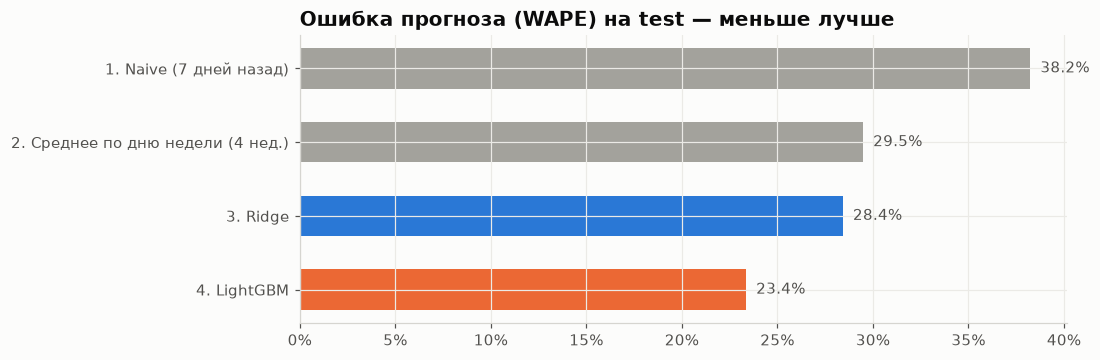

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.4))
order = res.index[::-1]
ax.barh(order, res.loc[order, "WAPE"], color=[ORANGE if n.startswith("4") else BLUE if n.startswith("3") else GRAY for n in order], height=0.55)
for yv, v in enumerate(res.loc[order, "WAPE"]):
    ax.text(v, yv, f"  {v:.1%}", va="center", fontsize=10, color=INK2)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Ошибка прогноза (WAPE) на test — меньше лучше")
save(fig, "08_model_wape"); plt.show()

**Что видно:** 
- **LightGBM — лучший:** в среднем ошибается на **~133 тыс. сом** в день на банкомат при средней выдаче ~570 тыс. Это **WAPE 23,4%**: если сложить все ошибки за полгода, они составят около четверти всей выданной суммы.
- Это на **21% точнее** лучшей простой модели (среднее по дню недели, 29,5%) и почти **в 1,6 раза точнее** naive (38,2%).
- **Ridge почти не лучше простого среднего** (28,4% против 29,5%). Линейная модель не умеет учитывать сочетания вроде «офис + выходной = провал» или «Соцфонд + день пенсий = пик», а именно они важны в этих данных (мы видели это в EDA).
- **Naive хуже всех:** неделю назад мог быть день зарплаты или пенсий, и прогноз «копирует» чужой пик.
- **Дни сбоев** (пустой банкомат или простой, 301 день в test) — ошибка выше у всех моделей, но порядок тот же: LightGBM 26,3%. Модель прогнозирует *спрос*, а в эти дни банкомат физически не мог его обслужить, поэтому ошибка там ожидаемо больше. Для бизнеса это и есть смысл прогноза: знать заранее, что банкомат опустеет, и загрузить его.
- **Почему 23% — это не «плохо»:** выдача одного банкомата за один день очень шумная (пришёл один клиент за 200 тыс. — и уже +30%). Даже идеально зная все закономерности, часть этого шума предсказать нельзя.

### 5.1 Где модели ошибаются: по типам дней и типам точек

In [11]:
test = test.assign(**{f"pred_{i}": p for i, p in enumerate(preds.values(), 1)})
test["тип дня"] = np.select(
    [test.is_pre_holiday == 1, test.is_holiday == 1, test.is_pension_day == 1, test.is_payday == 1],
    ["предпраздник", "праздник", "пенсия", "зарплата"], "обычный")

def wape_by(col):
    rows = {}
    for key, part in test.groupby(col):
        rows[key] = {"строк": len(part),
                     "Naive": metrics(part[TARGET], part.pred_1)["WAPE"],
                     "Ср. по дню недели": metrics(part[TARGET], part.pred_2)["WAPE"],
                     "Ridge": metrics(part[TARGET], part.pred_3)["WAPE"],
                     "LightGBM": metrics(part[TARGET], part.pred_4)["WAPE"]}
    return pd.DataFrame(rows).T

pf = lambda v: f"{v:.1%}"
print("WAPE по типу дня:")
print(wape_by("тип дня").to_string(formatters={c: pf for c in ["Naive", "Ср. по дню недели", "Ridge", "LightGBM"]} | {"строк": "{:.0f}".format}))
print("\nWAPE по типу точки:")
print(wape_by("atm_type").to_string(formatters={c: pf for c in ["Naive", "Ср. по дню недели", "Ridge", "LightGBM"]} | {"строк": "{:.0f}".format}))

bias = (test.pred_4 - test[TARGET]).groupby(test["тип дня"]).sum() / test[TARGET].groupby(test["тип дня"]).sum()
print("\nСмещение LightGBM (+ = переоценивает, − = недооценивает):"); print(bias.map(pf).to_string())

WAPE по типу дня:
             строк Naive Ср. по дню недели Ridge LightGBM
зарплата      2115 33.4%             28.4% 30.9%    23.6%
обычный      15411 38.0%             27.5% 26.1%    23.4%
пенсия        3500 40.3%             33.1% 32.2%    22.8%
праздник       350 38.0%             45.5% 35.9%    27.3%
предпраздник   350 48.5%             44.8% 39.3%    23.3%

WAPE по типу точки:
                 строк Naive Ср. по дню недели Ridge LightGBM
highway_gas       2554 29.5%             23.7% 30.9%    24.3%
office_business   3158 53.2%             39.4% 36.9%    24.8%
pension_social    2908 65.5%             50.1% 41.0%    24.6%
residential       4747 35.9%             27.7% 24.7%    23.8%
shopping_mall     2541 32.4%             25.4% 25.8%    22.7%
tourist_center    1828 28.2%             22.7% 26.4%    23.7%
transport_market  3990 30.4%             23.7% 23.2%    22.0%

Смещение LightGBM (+ = переоценивает, − = недооценивает):
тип дня
зарплата        -1.0%
обычный          0.1%
пенсия

**Что видно:** 
- **LightGBM держит одинаковое качество (~23%) в любой тип дня**, а простые модели сильно проседают в особые дни:
  - **предпраздник:** naive 48,5%, среднее по дню недели 44,8% → LightGBM **23,3%**;
  - **праздник:** среднее по дню недели 45,5% → LightGBM 27,3%;
  - **пенсии:** 33–40% → LightGBM 22,8%.
  Причина: LightGBM видит в календаре, что завтра особый день, а простые модели только повторяют прошлое.
- **По типам точек** разница ещё больше: у банкоматов **Соцфонда** naive ошибается на 65%, а LightGBM на 25%; у **офисов** 53% → 25%. Это точки с самыми резкими пиками (пенсии, будни/выходные).
- На «спокойных» точках (АЗС, туристические места) простое среднее по дню недели почти не уступает LightGBM — там и предсказывать особо нечего.
- **Смещение маленькое:** в обычные дни модель в среднем не завышает и не занижает (0,1%). В праздники немного переоценивает (+5,7%), в предпраздники недооценивает (−4,5%) — праздников в train всего около 20, модели мало примеров.

## 6. Что важно для LightGBM

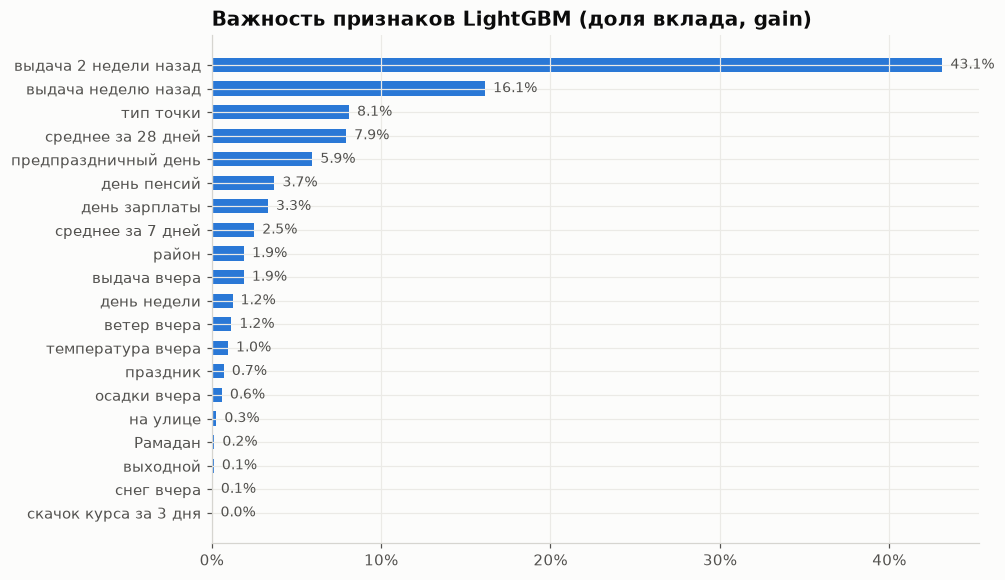

lag_14              43.1
lag_7               16.1
atm_type             8.1
roll_mean_28         7.9
is_pre_holiday       5.9
is_pension_day       3.7
is_payday            3.3
roll_mean_7          2.5
district_id          1.9
lag_1                1.9
dow                  1.2
wind_max_lag1        1.2
temp_avg_lag1        1.0
is_holiday           0.7
precip_mm_lag1       0.6
is_street            0.3
is_ramadan           0.2
is_weekend           0.1
snowfall_mm_lag1     0.1
fx_shock_last3       0.0


In [12]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum()).sort_values()
names_ru = {
    "roll_mean_7": "среднее за 7 дней", "roll_mean_28": "среднее за 28 дней",
    "lag_1": "выдача вчера", "lag_7": "выдача неделю назад", "lag_14": "выдача 2 недели назад",
    "dow": "день недели", "atm_type": "тип точки", "district_id": "район",
    "is_holiday": "праздник", "is_pre_holiday": "предпраздничный день", "is_payday": "день зарплаты",
    "is_pension_day": "день пенсий", "is_ramadan": "Рамадан", "is_weekend": "выходной",
    "is_street": "на улице", "fx_shock_last3": "скачок курса за 3 дня",
    "temp_avg_lag1": "температура вчера", "precip_mm_lag1": "осадки вчера",
    "snowfall_mm_lag1": "снег вчера", "wind_max_lag1": "ветер вчера",
}
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([names_ru.get(i, i) for i in imp.index], imp.values, color=BLUE, height=0.6)
for yv, v in enumerate(imp.values):
    ax.text(v, yv, f"  {v:.1%}", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Важность признаков LightGBM (доля вклада, gain)")
save(fig, "09_feature_importance"); plt.show()
print((imp.sort_values(ascending=False) * 100).round(1).to_string())

**Что видно:** 
- **Самое важное — история самого банкомата:** выдача 2 недели назад, неделю назад и средние за 7 и 28 дней — вместе **~70%** вклада.
- **Почему «2 недели назад» важнее, чем «неделю назад»?** В этих данных зарплату платят **дважды в месяц** (10–14 и 25–27 числа) — примерно каждые 2 недели. Поэтому день 14 дней назад чаще оказывается в той же фазе зарплатного цикла, чем день неделю назад. Мы это проверили: связь с выдачей 14 дней назад (автокорреляция 0,38) сильнее, чем 7 дней назад (0,27).
- Дальше — **тип точки (8%)** и **календарь**: предпраздник (5,9%), пенсии (3,7%), зарплата (3,3%).
- **Погода и курс почти не важны** (вместе ~3%). Это ожидаемо: в EDA погода влияла только в редкие сильные морозы, а скачков курса в тестовом периоде не было вовсе — модель учится на трёх случаях за 1,5 года.
- Важность «по вкладу» (gain) — грубая оценка; признаки, которые дублируют друг друга (например, лаги и средние), делят вклад между собой.

## 7. Прогноз против факта для банкоматов разных типов

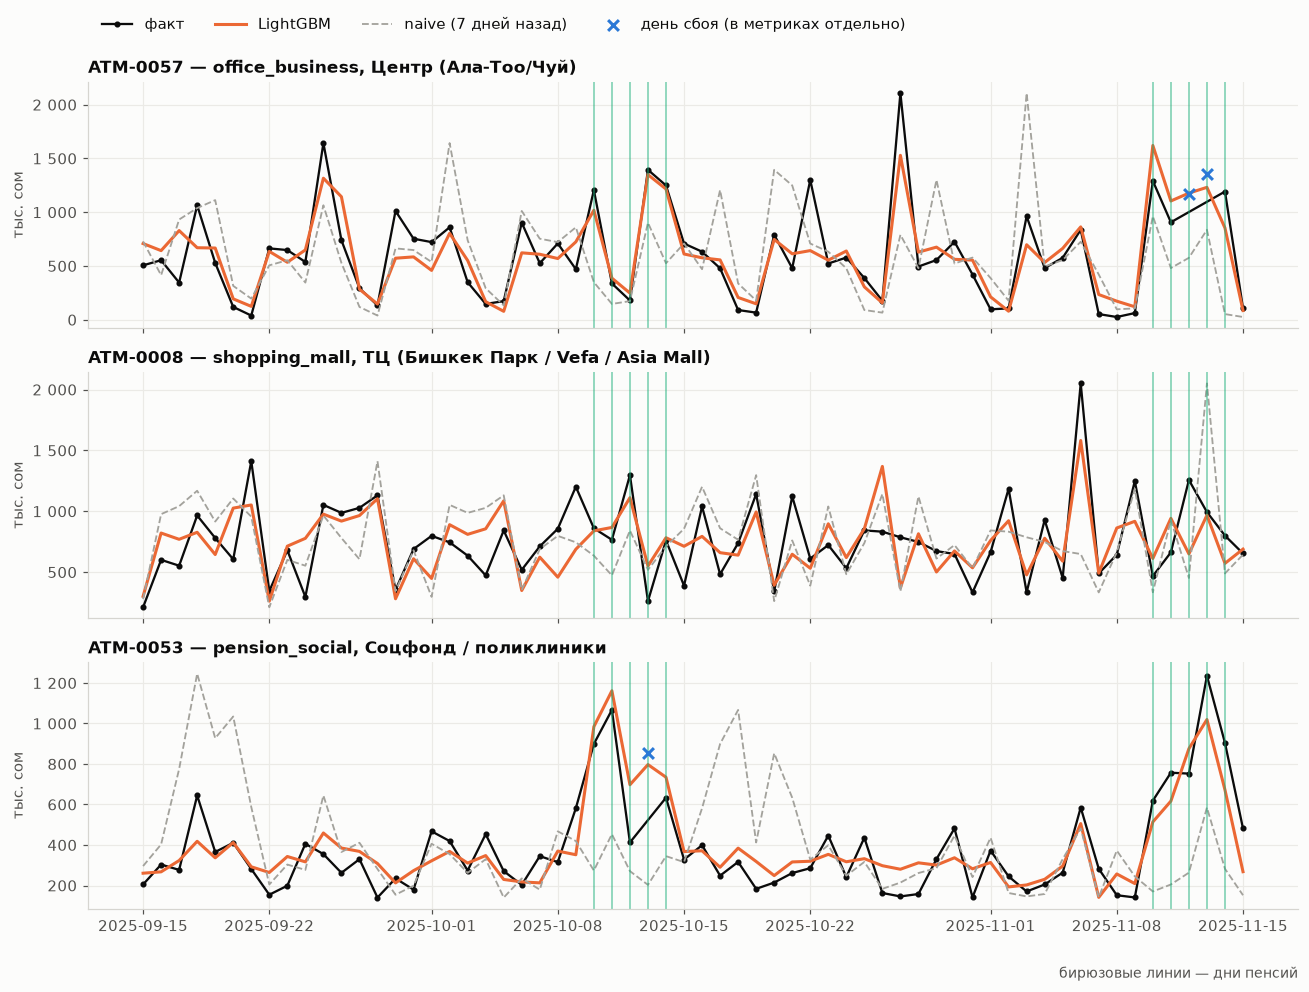

ATM-0057 (office_business): WAPE LightGBM 25.0% vs naive 48.4%, средняя выдача 609 тыс.
ATM-0008 (shopping_mall): WAPE LightGBM 24.3% vs naive 35.7%, средняя выдача 788 тыс.
ATM-0053 (pension_social): WAPE LightGBM 24.9% vs naive 66.7%, средняя выдача 403 тыс.


In [13]:
# Берём по одному «типичному» банкомату (средний по объёму внутри своего типа)
picks = []
for t in ["office_business", "shopping_mall", "pension_social"]:
    vol = test[test.atm_type == t].groupby("atm_id")[TARGET].mean()
    picks.append((vol - vol.median()).abs().idxmin())

window = (pd.Timestamp("2025-09-15"), pd.Timestamp("2025-11-15"))
full = pd.concat([test, test_disrupted.assign(**{f"pred_{i}": p for i, p in enumerate(preds_dis.values(), 1)})])

fig, axes = plt.subplots(len(picks), 1, figsize=(12, 9), sharex=True)
for ax, atm in zip(axes, picks):
    s = full[(full.atm_id == atm) & full.date.between(*window)].sort_values("date")
    ok = s[~s.is_disrupted]
    ax.plot(ok.date, ok[TARGET], color=INK, linewidth=1.5, marker="o", markersize=3, label="факт")
    ax.plot(s.date, s.pred_4, color=ORANGE, label="LightGBM")
    ax.plot(s.date, s.pred_1, color=GRAY, linewidth=1.2, linestyle="--", label="naive (7 дней назад)")
    bad = s[s.is_disrupted]
    if len(bad):
        ax.scatter(bad.date, bad[TARGET], color=BLUE, marker="x", s=50, zorder=5, label="день сбоя (в метриках отдельно)")
    for d in s[s.is_pension_day == 1].date:
        ax.axvline(d, color=AQUA, linewidth=1, alpha=0.6)
    a = s.iloc[0]
    ax.set_title(f"{atm} — {a.atm_type}, {a.district_name}", fontsize=11)
    ax.yaxis.set_major_formatter(thousands); ax.set_ylabel("тыс. сом")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.32), ncol=4)
axes[-1].text(1, -0.28, "бирюзовые линии — дни пенсий", transform=axes[-1].transAxes, ha="right", fontsize=9, color=INK2)
fig.tight_layout(); save(fig, "10_forecast_vs_actual"); plt.show()

for atm in picks:
    part = test[test.atm_id == atm]
    m4, m1 = metrics(part[TARGET], part.pred_4), metrics(part[TARGET], part.pred_1)
    print(f"{atm} ({part.atm_type.iloc[0]}): WAPE LightGBM {m4['WAPE']:.1%} vs naive {m1['WAPE']:.1%}, "
          f"средняя выдача {part[TARGET].mean()/1e3:,.0f} тыс.")

**Что видно:** 
- **Офис (ATM-0057, Центр):** модель хорошо ловит провалы в выходные (почти до нуля) и пики в будни. Naive часто «опаздывает» на неделю.
- **ТЦ (ATM-0008):** самый шумный банкомат — модель повторяет общий ритм, но отдельные пики (2 млн в один день) не угадывает. Это случайные всплески, их никто не предскажет.
- **Соцфонд (ATM-0053):** самая наглядная разница. В дни пенсий (бирюзовые линии) выдача вырастает в 3–4 раза, и **LightGBM заранее предсказывает этот пик**, а naive ставит пик через неделю после пенсий, когда он уже прошёл.
- Ошибки LightGBM по этим трём банкоматам: 24–25% против 36–67% у naive.
- Синие крестики — дни, когда банкомат опустел или был в простое. Модель в такие дни прогнозирует высокий спрос: это ровно тот сигнал, который нужен для инкассации.

## 8. Итог

**Главный результат:** LightGBM прогнозирует выдачу на завтра с ошибкой **WAPE 23,4%** — на **21% лучше** лучшей простой модели и в 1,6 раза лучше naive.

| Модель | MAE, сом | MAPE | WAPE |
|---|---:|---:|---:|
| Naive (7 дней назад) | 218 тыс. | 44,8% | 38,2% |
| Среднее по дню недели (4 нед.) | 168 тыс. | 36,5% | 29,5% |
| Ridge | 162 тыс. | 38,8% | 28,4% |
| **LightGBM** | **133 тыс.** | **28,4%** | **23,4%** |

**Что запомнить для созвона:**
1. Главное, на что опирается модель, — **история самого банкомата** (особенно 2 недели назад из-за зарплатного цикла) и **календарь** (предпраздник, пенсии, зарплата).
2. Преимущество LightGBM — в **особых днях и необычных точках**: перед праздником и у Соцфонда в дни пенсий он ошибается вдвое меньше простых моделей.
3. **Погода и курс почти ничего не дают** — сильные морозы и скачки курса слишком редки.
4. Модель проверена честно: учили на данных до июля 2025, проверяли на следующем полугодии, без подглядывания в будущее.

**Ограничения:**
- Данные синтетические — на реальных данных ошибка, скорее всего, будет выше.
- Скачки курса предсказать заранее нельзя, в test их не было, поэтому качество в такие дни не проверено.
- Погоду мы брали вчерашнюю; с настоящим прогнозом погоды на завтра морозные дни можно было бы ловить лучше.

**Что можно улучшить дальше:**
- Добавить **лаг 28 дней и день месяца** — они лучше ловят зарплатный и пенсионный циклы.
- Сделать признаки «дней до праздника / до пенсии».
- Подобрать параметры LightGBM и попробовать предсказывать отношение к среднему банкомата вместо суммы в сомах.
- Перейти от прогноза к решению: **на сколько дней хватит денег в банкомате** и когда его загружать.